## Modelling

In [1]:
!pip install pandas numpy matplotlib seaborn gensim scikit-learn joblib

## Modelling Naive Bayes + Preprocesing

KLASIFIKASI BERITA DETIK
Word2Vec Skip-gram + Gaussian Naive Bayes
Tanpa PCA dan tanpa model pembanding

Folder kerja : d:\webmining
Dataset      : d:\webmining\Data\detik_preprocessed.csv
Folder hasil : d:\webmining\hasil_skipgram

TAHAP 1: MEMUAT DATASET

Ukuran dataset awal: (199, 3)
Kolom tersedia: ['id', 'isi_berita_clean', 'label']

Distribusi label sebelum pembersihan:
label
sport      100
finance     99
Name: count, dtype: int64

Kolom teks yang digunakan: isi_berita_clean
Jumlah data setelah pembersihan: 198
Jumlah berita duplikat dihapus: 1

Distribusi kelas:
label
Sport      99
Finance    99
Name: count, dtype: int64

Contoh teks:
 id                                                                                                                                                                                                                                                                                                                                                           

Pelatihan Word2Vec selesai.
Metode             : Skip-gram
Vector size        : 100
Window              : 5
Minimum count       : 1
Epochs              : 20
Jumlah kata unik    : 4416

Contoh kosakata:
['dan', 'yang', 'di', 'ini', 'untuk', 'dengan', 'dari', 'dalam', 'jadi', 'indonesia', 'pada', 'sebut', 'itu', 'juga', 'laku', 'ada', 'pasar', 'serta', 'balap', 'usaha']

Model Word2Vec disimpan.

TAHAP 4: ANALISIS VEKTOR KATA

Kata target: saham
Dimensi vektor: 100
Vektor kata:
[ 0.04668595  0.05728834 -0.6165915   0.1513645  -0.08161372  0.6861765
 -0.46946275  1.0198605  -0.8905655  -0.4895906  -0.34789625  0.05844148
  0.39975598 -0.33908537 -0.4374031  -0.4740433  -0.3104465   0.03141099
 -1.0488063  -1.1762099   0.13359682 -0.6907145  -0.11750276  0.18863691
  0.49259922 -0.35272428  0.32508928  0.8699301  -0.14729002  0.00325431
 -0.3633901  -0.19711229 -0.05291343 -0.2738407   0.10862587  0.75196266
 -0.9227987  -0.19978516 -0.17050949  0.45912924 -0.41887686 -0.68875533
  0.97490

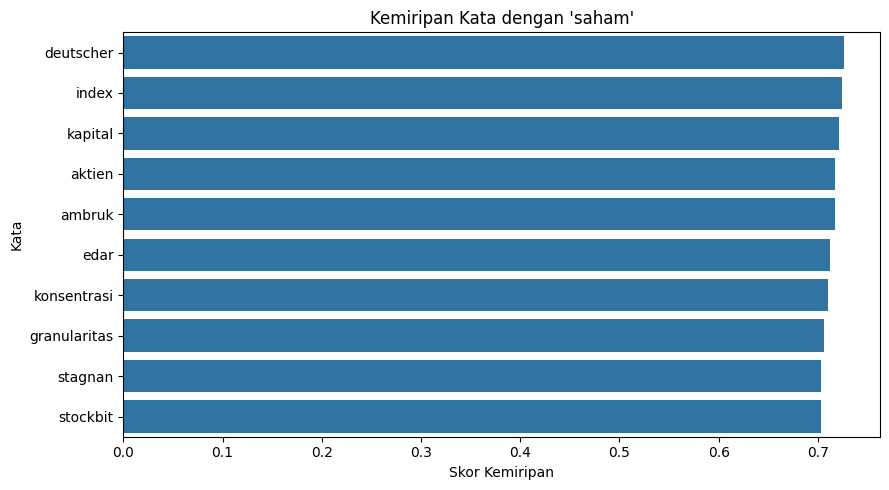


Hasil analisis vektor kata disimpan.

TAHAP 5: MEMBENTUK VEKTOR DOKUMEN
Bentuk X_train_vec: (158, 100)
Bentuk X_test_vec : (40, 100)
Vektor nol data latih: 0
Vektor nol data uji  : 0

Contoh lima dimensi pertama dari tiga dokumen latih:
[[-0.06050626  0.02396429 -0.11456133  0.0991246  -0.03907755]
 [-0.02499629  0.13800843 -0.21535544  0.13401143 -0.13507538]
 [ 0.02892541  0.05683252 -0.08235133  0.17337804 -0.16902435]]

Vektor dokumen berhasil disimpan.

TAHAP 6: KLASIFIKASI GAUSSIAN NAIVE BAYES
Model berhasil dilatih.
Representasi teks : Word2Vec Skip-gram
Algoritma         : Gaussian Naive Bayes
PCA               : Tidak digunakan
Jumlah fitur      : 100

Jumlah data latih per kelas:
  Kelas  Jumlah
Finance      79
  Sport      79

Model GaussianNB disimpan.

TAHAP 7: EVALUASI WORD2VEC SKIP-GRAM + GAUSSIANNB

A. METRIK EVALUASI KESELURUHAN
---------------------------------------------------------------------------
Model: Word2Vec Skip-gram + GaussianNB
Accuracy: 0.9500 (95.00%)


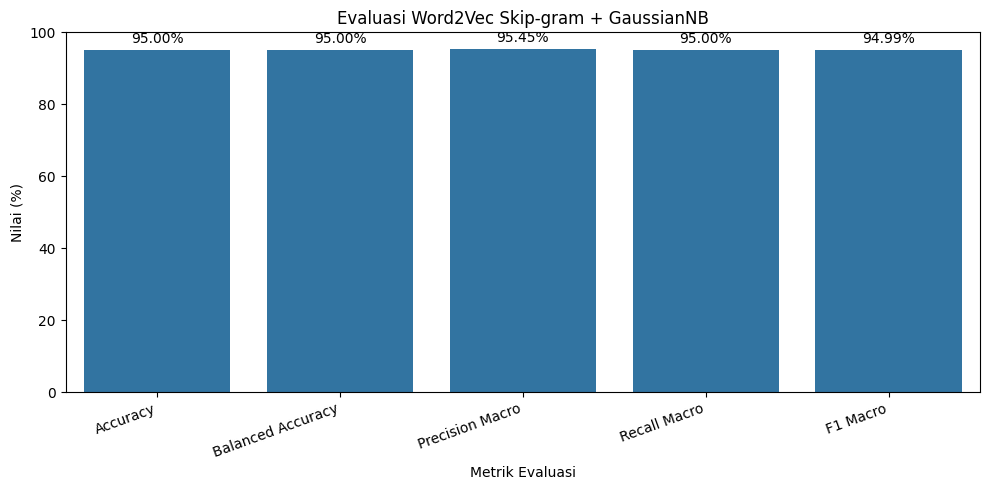


TAHAP 8: CONFUSION MATRIX
Urutan kelas: Finance, Sport

Confusion matrix:
[[20  0]
 [ 2 18]]


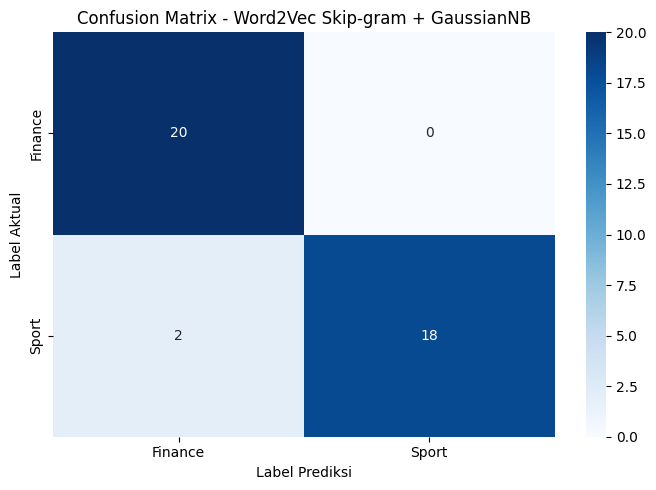


TAHAP 9: HASIL PREDIKSI DATA UJI

Sepuluh contoh hasil prediksi:
 id                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                   

In [ ]:

# ============================================================
# KLASIFIKASI BERITA DETIK
# WORD2VEC SKIP-GRAM + GAUSSIAN NAIVE BAYES
# TANPA PCA DAN TANPA MODEL PEMBANDING
# ============================================================

import os
import random
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

warnings.filterwarnings("ignore")

# ============================================================
# KONFIGURASI
# ============================================================

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Path dataset relatif terhadap folder kerja notebook
BASE_DIR = Path.cwd()
DATA_PATH = BASE_DIR / "Data" / "detik_preprocessed.csv"
OUTPUT_DIR = BASE_DIR / "hasil_skipgram"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LABEL_MAP = {
    "finance": 0,
    "sport": 1
}

LABEL_NAMES = ["Finance", "Sport"]

print("=" * 75)
print("KLASIFIKASI BERITA DETIK")
print("Word2Vec Skip-gram + Gaussian Naive Bayes")
print("Tanpa PCA dan tanpa model pembanding")
print("=" * 75)

print("\nFolder kerja :", BASE_DIR)
print("Dataset      :", DATA_PATH)
print("Folder hasil :", OUTPUT_DIR)


# ============================================================
# TAHAP 1 — MEMUAT DAN MEMERIKSA DATASET
# ============================================================

print("\n" + "=" * 75)
print("TAHAP 1: MEMUAT DATASET")
print("=" * 75)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset tidak ditemukan: {DATA_PATH}\n"
        "Pastikan detik_preprocessed.csv berada di folder Data."
    )

df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

print("\nUkuran dataset awal:", df.shape)
print("Kolom tersedia:", df.columns.tolist())

# Deteksi kolom teks
if "isi_berita_clean" in df.columns:
    TEXT_COLUMN = "isi_berita_clean"
elif "isi_berita" in df.columns:
    TEXT_COLUMN = "isi_berita"
else:
    raise KeyError(
        "Kolom teks tidak ditemukan. "
        f"Kolom yang tersedia: {df.columns.tolist()}"
    )

if "label" not in df.columns:
    raise KeyError(
        "Kolom 'label' tidak ditemukan."
    )

if "id" not in df.columns:
    df.insert(0, "id", range(1, len(df) + 1))

# Seragamkan nama kolom teks untuk tahap berikutnya
df = df.rename(
    columns={TEXT_COLUMN: "isi_berita_clean"}
)

df["isi_berita_clean"] = (
    df["isi_berita_clean"]
    .fillna("")
    .astype(str)
    .str.strip()
)

df["label"] = (
    df["label"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

print("\nDistribusi label sebelum pembersihan:")
print(df["label"].value_counts(dropna=False))

# Hanya gunakan kelas Finance dan Sport
df = df[df["label"].isin(LABEL_MAP.keys())].copy()

# Hapus teks kosong
df = df[df["isi_berita_clean"].ne("")].copy()

# Hapus berita duplikat
jumlah_sebelum = len(df)

df = df.drop_duplicates(
    subset=["isi_berita_clean"]
).copy()

jumlah_duplikat = jumlah_sebelum - len(df)

# Konversi label menjadi angka
df["label_id"] = df["label"].map(LABEL_MAP).astype(int)

# Tokenisasi berdasarkan spasi.
# Teks diasumsikan telah melalui preprocessing sebelumnya.
df["tokens"] = df["isi_berita_clean"].apply(
    lambda text: text.lower().split()
)

df = df[df["tokens"].map(len) > 0].copy()
df.reset_index(drop=True, inplace=True)

if df["label_id"].nunique() != 2:
    raise ValueError(
        "Dataset harus memiliki kedua kelas: Finance dan Sport."
    )

if df["label_id"].value_counts().min() < 2:
    raise ValueError(
        "Setiap kelas minimal memiliki dua berita."
    )

print("\nKolom teks yang digunakan:", TEXT_COLUMN)
print("Jumlah data setelah pembersihan:", len(df))
print("Jumlah berita duplikat dihapus:", jumlah_duplikat)

print("\nDistribusi kelas:")
print(
    df["label"].value_counts().rename(
        index={"finance": "Finance", "sport": "Sport"}
    )
)

print("\nContoh teks:")
print(
    df[["id", "isi_berita_clean", "label"]]
    .head(5)
    .to_string(index=False)
)

df.to_csv(
    OUTPUT_DIR / "dataset_model.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nDataset model disimpan.")


# ============================================================
# TAHAP 2 — TRAIN-TEST SPLIT
# ============================================================

print("\n" + "=" * 75)
print("TAHAP 2: PEMBAGIAN DATA LATIH DAN DATA UJI")
print("=" * 75)

train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    stratify=df["label_id"]
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

y_train = train_df["label_id"].to_numpy()
y_test = test_df["label_id"].to_numpy()

print("Jumlah seluruh data :", len(df))
print("Jumlah data latih    :", len(train_df))
print("Jumlah data uji      :", len(test_df))

print("\nDistribusi data latih:")
print(
    train_df["label"].value_counts().rename(
        index={"finance": "Finance", "sport": "Sport"}
    )
)

print("\nDistribusi data uji:")
print(
    test_df["label"].value_counts().rename(
        index={"finance": "Finance", "sport": "Sport"}
    )
)

print("\nContoh data latih:")
print(train_df[["id", "label"]].head().to_string(index=False))

train_df.to_csv(
    OUTPUT_DIR / "data_latih.csv",
    index=False,
    encoding="utf-8-sig"
)

test_df.to_csv(
    OUTPUT_DIR / "data_uji.csv",
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# TAHAP 3 — WORD2VEC SKIP-GRAM
# ============================================================

print("\n" + "=" * 75)
print("TAHAP 3: PELATIHAN WORD2VEC SKIP-GRAM")
print("=" * 75)

sentences_train = train_df["tokens"].tolist()

w2v_model = Word2Vec(
    sentences=sentences_train,
    vector_size=100,
    window=5,
    min_count=1,
    workers=1,
    sg=1,
    seed=SEED,
    epochs=20
)

print("Pelatihan Word2Vec selesai.")
print("Metode             : Skip-gram")
print("Vector size        :", w2v_model.vector_size)
print("Window              :", w2v_model.window)
print("Minimum count       :", w2v_model.min_count)
print("Epochs              :", w2v_model.epochs)
print("Jumlah kata unik    :", len(w2v_model.wv))

print("\nContoh kosakata:")
print(w2v_model.wv.index_to_key[:20])

w2v_model.save(
    str(OUTPUT_DIR / "w2v_model.model")
)

print("\nModel Word2Vec disimpan.")


# ============================================================
# TAHAP 4 — VEKTOR KATA DAN KEMIRIPAN KATA
# ============================================================

print("\n" + "=" * 75)
print("TAHAP 4: ANALISIS VEKTOR KATA")
print("=" * 75)

target_word = "saham"

if target_word not in w2v_model.wv:
    # Cari kata yang tersedia sebagai contoh
    target_word = w2v_model.wv.index_to_key[0]
    print(
        "Kata 'saham' tidak ditemukan. "
        f"Kata contoh: '{target_word}'"
    )

word_vector = w2v_model.wv[target_word]

print("\nKata target:", target_word)
print("Dimensi vektor:", len(word_vector))
print("Vektor kata:")
print(word_vector)

print("\nLima nilai pertama:")
print(word_vector[:5])

if len(w2v_model.wv) > 1:
    similar_words = w2v_model.wv.most_similar(
        target_word,
        topn=min(10, len(w2v_model.wv) - 1)
    )
else:
    similar_words = []

similarity_df = pd.DataFrame(
    similar_words,
    columns=["kata", "skor_kemiripan"]
)

print("\nKata paling mirip:")
if similarity_df.empty:
    print("Tidak ada kata pembanding dalam kosakata.")
else:
    print(similarity_df.to_string(index=False))

vector_df = pd.DataFrame(
    [word_vector],
    columns=[
        f"dimensi_{i + 1}"
        for i in range(len(word_vector))
    ]
)

vector_df.insert(0, "kata", target_word)

vector_df.to_csv(
    OUTPUT_DIR / "hasil_vektor_kata_skipgram.csv",
    index=False,
    encoding="utf-8-sig"
)

similarity_df.to_csv(
    OUTPUT_DIR / "hasil_kemiripan_kata_skipgram.csv",
    index=False,
    encoding="utf-8-sig"
)

if not similarity_df.empty:
    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=similarity_df,
        x="skor_kemiripan",
        y="kata"
    )

    plt.title(f"Kemiripan Kata dengan '{target_word}'")
    plt.xlabel("Skor Kemiripan")
    plt.ylabel("Kata")
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "visualisasi_kemiripan_kata.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("\nHasil analisis vektor kata disimpan.")


# ============================================================
# TAHAP 5 — MEMBENTUK VEKTOR DOKUMEN
# ============================================================

print("\n" + "=" * 75)
print("TAHAP 5: MEMBENTUK VEKTOR DOKUMEN")
print("=" * 75)


def get_document_vector(tokens, model):
    """
    Vektor dokumen dihitung dari rata-rata vektor kata
    yang dikenal oleh model Word2Vec.
    """
    vectors = [
        model.wv[token]
        for token in tokens
        if token in model.wv
    ]

    if not vectors:
        return np.zeros(
            model.vector_size,
            dtype=np.float32
        )

    return np.mean(vectors, axis=0)


X_train_vec = np.vstack([
    get_document_vector(tokens, w2v_model)
    for tokens in train_df["tokens"]
])

X_test_vec = np.vstack([
    get_document_vector(tokens, w2v_model)
    for tokens in test_df["tokens"]
])

print("Bentuk X_train_vec:", X_train_vec.shape)
print("Bentuk X_test_vec :", X_test_vec.shape)

zero_train = int(np.all(X_train_vec == 0, axis=1).sum())
zero_test = int(np.all(X_test_vec == 0, axis=1).sum())

print("Vektor nol data latih:", zero_train)
print("Vektor nol data uji  :", zero_test)

print("\nContoh lima dimensi pertama dari tiga dokumen latih:")
print(X_train_vec[:3, :5])

if zero_train > 0 or zero_test > 0:
    print(
        "\nPERINGATAN: terdapat dokumen dengan vektor nol. "
        "Periksa kesesuaian preprocessing dan kosakata."
    )

train_vectors_df = pd.DataFrame(
    X_train_vec,
    columns=[
        f"dimensi_{i + 1}"
        for i in range(X_train_vec.shape[1])
    ]
)

train_vectors_df.insert(0, "id", train_df["id"].to_numpy())
train_vectors_df["label"] = train_df["label"].to_numpy()

test_vectors_df = pd.DataFrame(
    X_test_vec,
    columns=[
        f"dimensi_{i + 1}"
        for i in range(X_test_vec.shape[1])
    ]
)

test_vectors_df.insert(0, "id", test_df["id"].to_numpy())
test_vectors_df["label"] = test_df["label"].to_numpy()

train_vectors_df.to_csv(
    OUTPUT_DIR / "vektor_dokumen_latih.csv",
    index=False,
    encoding="utf-8-sig"
)

test_vectors_df.to_csv(
    OUTPUT_DIR / "vektor_dokumen_uji.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nVektor dokumen berhasil disimpan.")


# ============================================================
# TAHAP 6 — KLASIFIKASI GAUSSIAN NAIVE BAYES
# ============================================================

print("\n" + "=" * 75)
print("TAHAP 6: KLASIFIKASI GAUSSIAN NAIVE BAYES")
print("=" * 75)

model_gnb = GaussianNB()

model_gnb.fit(
    X_train_vec,
    y_train
)

print("Model berhasil dilatih.")
print("Representasi teks : Word2Vec Skip-gram")
print("Algoritma         : Gaussian Naive Bayes")
print("PCA               : Tidak digunakan")
print("Jumlah fitur      :", X_train_vec.shape[1])

print("\nJumlah data latih per kelas:")

print(
    pd.DataFrame({
        "Kelas": LABEL_NAMES,
        "Jumlah": [
            int(np.sum(y_train == 0)),
            int(np.sum(y_train == 1))
        ]
    }).to_string(index=False)
)

joblib.dump(
    model_gnb,
    OUTPUT_DIR / "gnb_model.pkl"
)

print("\nModel GaussianNB disimpan.")


# ============================================================
# TAHAP 7 — EVALUASI MODEL
# ============================================================

print("\n" + "=" * 75)
print("TAHAP 7: EVALUASI WORD2VEC SKIP-GRAM + GAUSSIANNB")
print("=" * 75)

y_pred = model_gnb.predict(X_test_vec)

accuracy = accuracy_score(y_test, y_pred)
balanced_acc = balanced_accuracy_score(y_test, y_pred)

precision_macro = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)

recall_macro = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)

f1_macro = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

precision_weighted = precision_score(
    y_test, y_pred, average="weighted", zero_division=0
)

recall_weighted = recall_score(
    y_test, y_pred, average="weighted", zero_division=0
)

f1_weighted = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

# Semua metrik disimpan sebagai angka 0–1
hasil_metrik = pd.DataFrame([{
    "Model": "Word2Vec Skip-gram + GaussianNB",
    "Accuracy": accuracy,
    "Balanced Accuracy": balanced_acc,
    "Precision Macro": precision_macro,
    "Recall Macro": recall_macro,
    "F1 Macro": f1_macro,
    "Precision Weighted": precision_weighted,
    "Recall Weighted": recall_weighted,
    "F1 Weighted": f1_weighted
}])

print("\nA. METRIK EVALUASI KESELURUHAN")
print("-" * 75)

for kolom in hasil_metrik.columns:
    if kolom == "Model":
        print(f"{kolom}: {hasil_metrik.iloc[0][kolom]}")
    else:
        nilai = hasil_metrik.iloc[0][kolom]
        print(f"{kolom}: {nilai:.4f} ({nilai * 100:.2f}%)")

# Classification report
print("\nB. CLASSIFICATION REPORT")
print("-" * 75)

report_dict = classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=LABEL_NAMES,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()

print(report_df.round(4).to_string())

# Simpan metrik dan classification report
hasil_metrik.to_csv(
    OUTPUT_DIR / "hasil_evaluasi.csv",
    index=False,
    encoding="utf-8-sig"
)

report_df.to_csv(
    OUTPUT_DIR / "classification_report.csv",
    encoding="utf-8-sig"
)

# Grafik metrik utama
metrik_plot = pd.DataFrame({
    "Metrik": [
        "Accuracy",
        "Balanced Accuracy",
        "Precision Macro",
        "Recall Macro",
        "F1 Macro"
    ],
    "Nilai": [
        accuracy,
        balanced_acc,
        precision_macro,
        recall_macro,
        f1_macro
    ]
})

metrik_plot["Persentase"] = metrik_plot["Nilai"] * 100

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=metrik_plot,
    x="Metrik",
    y="Persentase"
)

ax.set_ylim(0, 100)
ax.set_ylabel("Nilai (%)")
ax.set_xlabel("Metrik Evaluasi")
ax.set_title("Evaluasi Word2Vec Skip-gram + GaussianNB")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "grafik_evaluasi_skipgram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# TAHAP 8 — CONFUSION MATRIX
# ============================================================

print("\n" + "=" * 75)
print("TAHAP 8: CONFUSION MATRIX")
print("=" * 75)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

print("Urutan kelas: Finance, Sport")
print("\nConfusion matrix:")
print(cm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=LABEL_NAMES,
    yticklabels=LABEL_NAMES
)

plt.title("Confusion Matrix - Word2Vec Skip-gram + GaussianNB")
plt.xlabel("Label Prediksi")
plt.ylabel("Label Aktual")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "confusion_matrix_skipgram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# TAHAP 9 — HASIL PREDIKSI DATA UJI
# ============================================================

print("\n" + "=" * 75)
print("TAHAP 9: HASIL PREDIKSI DATA UJI")
print("=" * 75)

hasil_prediksi = test_df[
    ["id", "isi_berita_clean", "label"]
].copy()

hasil_prediksi["label_aktual_id"] = y_test
hasil_prediksi["label_prediksi_id"] = y_pred

hasil_prediksi["label_aktual"] = (
    hasil_prediksi["label_aktual_id"]
    .map({0: "Finance", 1: "Sport"})
)

hasil_prediksi["label_prediksi"] = (
    hasil_prediksi["label_prediksi_id"]
    .map({0: "Finance", 1: "Sport"})
)

hasil_prediksi["hasil"] = np.where(
    hasil_prediksi["label_aktual_id"]
    == hasil_prediksi["label_prediksi_id"],
    "Benar",
    "Salah"
)

print("\nSepuluh contoh hasil prediksi:")
print(hasil_prediksi.head(10).to_string(index=False))

print("\nRingkasan hasil prediksi:")
print(hasil_prediksi["hasil"].value_counts())

hasil_prediksi.to_csv(
    OUTPUT_DIR / "hasil_prediksi_data_uji.csv",
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# TAHAP 10 — SIMPAN MODEL DAN METADATA
# ============================================================

print("\n" + "=" * 75)
print("TAHAP 10: SIMPAN MODEL DAN METADATA")
print("=" * 75)

metadata = {
    "model": "GaussianNB",
    "representasi_teks": "Word2Vec Skip-gram",
    "vector_size": 100,
    "window": 5,
    "min_count": 1,
    "sg": 1,
    "epochs": 20,
    "pca_used": False,
    "label_map": LABEL_MAP,
    "label_names": LABEL_NAMES,
    "random_seed": SEED
}

joblib.dump(
    metadata,
    OUTPUT_DIR / "metadata_model.pkl"
)

print("Model dan metadata berhasil disimpan.")


# ============================================================
# TAHAP 11 — PREDIKSI BERITA BARU
# ============================================================

print("\n" + "=" * 75)
print("TAHAP 11: PREDIKSI BERITA BARU")
print("=" * 75)


def prediksi_berita_baru(teks, model_w2v, model_gnb):
    if not isinstance(teks, str) or not teks.strip():
        raise ValueError("Teks berita tidak boleh kosong.")

    # Teks sebaiknya telah melalui preprocessing yang sama
    tokens = teks.lower().split()

    jumlah_token_dikenal = sum(
        token in model_w2v.wv
        for token in tokens
    )

    if jumlah_token_dikenal == 0:
        raise ValueError(
            "Tidak ada token yang dikenal Word2Vec. "
            "Gunakan teks dengan preprocessing yang sama "
            "seperti dataset pelatihan."
        )

    vector = get_document_vector(tokens, model_w2v)
    vector = vector.reshape(1, -1)

    prediksi_id = int(model_gnb.predict(vector)[0])
    probabilitas = model_gnb.predict_proba(vector)[0]

    return {
        "teks": teks,
        "jumlah_token": len(tokens),
        "jumlah_token_dikenal": jumlah_token_dikenal,
        "prediksi": LABEL_NAMES[prediksi_id],
        "probabilitas_finance": float(probabilitas[0]),
        "probabilitas_sport": float(probabilitas[1])
    }


berita_uji = (
    "IHSG bergerak menguat seiring peningkatan volume "
    "transaksi saham di pasar modal"
)

try:
    hasil_berita_baru = prediksi_berita_baru(
        berita_uji,
        w2v_model,
        model_gnb
    )

    print("\nTeks:", hasil_berita_baru["teks"])
    print("Prediksi:", hasil_berita_baru["prediksi"])
    print(
        "Probabilitas Finance:",
        f"{hasil_berita_baru['probabilitas_finance']:.4f}"
    )
    print(
        "Probabilitas Sport:",
        f"{hasil_berita_baru['probabilitas_sport']:.4f}"
    )

    pd.DataFrame([hasil_berita_baru]).to_csv(
        OUTPUT_DIR / "hasil_prediksi_berita_baru.csv",
        index=False,
        encoding="utf-8-sig"
    )

except ValueError as error:
    print("Prediksi tidak dapat dilakukan:", error)


# ============================================================
# TAHAP 12 — RINGKASAN FILE OUTPUT
# ============================================================

print("\n" + "=" * 75)
print("TAHAP 12: RINGKASAN OUTPUT")
print("=" * 75)

for filepath in sorted(OUTPUT_DIR.iterdir()):
    if filepath.is_file():
        print(
            f"{filepath.name} "
            f"({filepath.stat().st_size / 1024:.2f} KB)"
        )

print("\nLokasi hasil:", OUTPUT_DIR.resolve())


## Modelling Naive Bayes + Preprocesing (Tanpa Stopword Removal)

KLASIFIKASI BERITA DETIK
Word2Vec Skip-gram + Gaussian Naive Bayes
Tanpa PCA dan tanpa model pembanding

Folder kerja : d:\webmining
Dataset      : d:\webmining\Data\detik_preprocessed-TanpaStopword.csv
Folder hasil : d:\webmining\hasil_skipgram

TAHAP 1: MEMUAT DATASET

Ukuran dataset awal: (199, 3)
Kolom tersedia: ['id', 'isi_berita_clean', 'label']

Distribusi label sebelum pembersihan:
label
sport      100
finance     99
Name: count, dtype: int64

Kolom teks yang digunakan: isi_berita_clean
Jumlah data setelah pembersihan: 198
Jumlah berita duplikat dihapus: 1

Distribusi kelas:
label
Sport      99
Finance    99
Name: count, dtype: int64

Contoh teks:
 id                                                                                                                                                                                                                                                                                                                                             

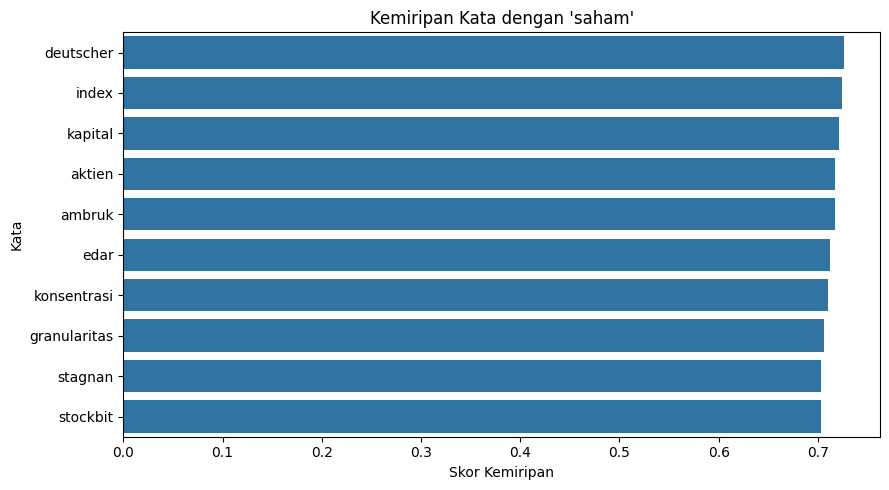


Hasil analisis vektor kata disimpan.

TAHAP 5: MEMBENTUK VEKTOR DOKUMEN
Bentuk X_train_vec: (158, 100)
Bentuk X_test_vec : (40, 100)
Vektor nol data latih: 0
Vektor nol data uji  : 0

Contoh lima dimensi pertama dari tiga dokumen latih:
[[-0.06050626  0.02396429 -0.11456133  0.0991246  -0.03907755]
 [-0.02499629  0.13800843 -0.21535544  0.13401143 -0.13507538]
 [ 0.02892541  0.05683252 -0.08235133  0.17337804 -0.16902435]]

Vektor dokumen berhasil disimpan.

TAHAP 6: KLASIFIKASI GAUSSIAN NAIVE BAYES
Model berhasil dilatih.
Representasi teks : Word2Vec Skip-gram
Algoritma         : Gaussian Naive Bayes
PCA               : Tidak digunakan
Jumlah fitur      : 100

Jumlah data latih per kelas:
  Kelas  Jumlah
Finance      79
  Sport      79

Model GaussianNB disimpan.

TAHAP 7: EVALUASI WORD2VEC SKIP-GRAM + GAUSSIANNB

A. METRIK EVALUASI KESELURUHAN
---------------------------------------------------------------------------
Model: Word2Vec Skip-gram + GaussianNB
Accuracy: 0.9500 (95.00%)


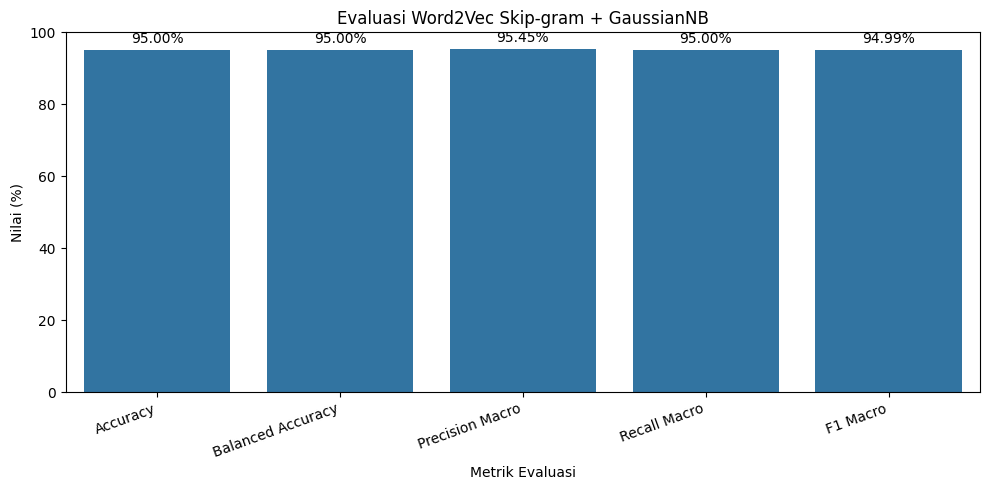


TAHAP 8: CONFUSION MATRIX
Urutan kelas: Finance, Sport

Confusion matrix:
[[20  0]
 [ 2 18]]


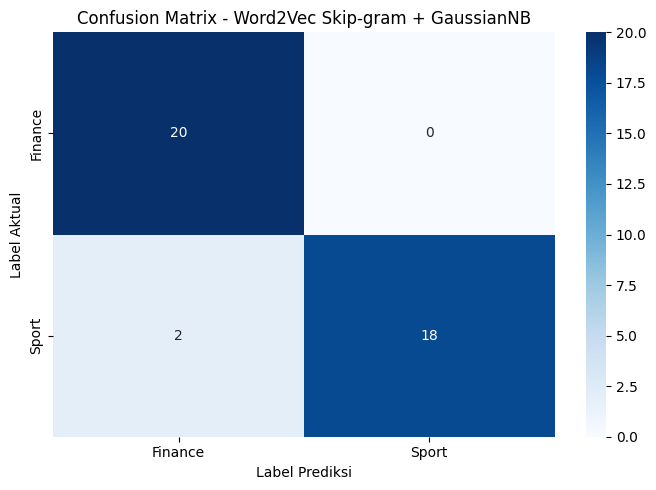


TAHAP 9: HASIL PREDIKSI DATA UJI

Sepuluh contoh hasil prediksi:
 id                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                   

In [6]:

# ============================================================
# KLASIFIKASI BERITA DETIK
# WORD2VEC SKIP-GRAM + GAUSSIAN NAIVE BAYES
# TANPA PCA DAN TANPA MODEL PEMBANDING
# ============================================================

import os
import random
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

warnings.filterwarnings("ignore")

# ============================================================
# KONFIGURASI
# ============================================================

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Path dataset relatif terhadap folder kerja notebook
BASE_DIR = Path.cwd()
DATA_PATH = BASE_DIR / "Data" / "detik_preprocessed-TanpaStopword.csv"
OUTPUT_DIR = BASE_DIR / "hasil_skipgram"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LABEL_MAP = {
    "finance": 0,
    "sport": 1
}

LABEL_NAMES = ["Finance", "Sport"]

print("=" * 75)
print("KLASIFIKASI BERITA DETIK")
print("Word2Vec Skip-gram + Gaussian Naive Bayes")
print("Tanpa PCA dan tanpa model pembanding")
print("=" * 75)

print("\nFolder kerja :", BASE_DIR)
print("Dataset      :", DATA_PATH)
print("Folder hasil :", OUTPUT_DIR)


# ============================================================
# TAHAP 1 — MEMUAT DAN MEMERIKSA DATASET
# ============================================================

print("\n" + "=" * 75)
print("TAHAP 1: MEMUAT DATASET")
print("=" * 75)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset tidak ditemukan: {DATA_PATH}\n"
        "Pastikan detik_preprocessed.csv berada di folder Data."
    )

df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

print("\nUkuran dataset awal:", df.shape)
print("Kolom tersedia:", df.columns.tolist())

# Deteksi kolom teks
if "isi_berita_clean" in df.columns:
    TEXT_COLUMN = "isi_berita_clean"
elif "isi_berita" in df.columns:
    TEXT_COLUMN = "isi_berita"
else:
    raise KeyError(
        "Kolom teks tidak ditemukan. "
        f"Kolom yang tersedia: {df.columns.tolist()}"
    )

if "label" not in df.columns:
    raise KeyError(
        "Kolom 'label' tidak ditemukan."
    )

if "id" not in df.columns:
    df.insert(0, "id", range(1, len(df) + 1))

# Seragamkan nama kolom teks untuk tahap berikutnya
df = df.rename(
    columns={TEXT_COLUMN: "isi_berita_clean"}
)

df["isi_berita_clean"] = (
    df["isi_berita_clean"]
    .fillna("")
    .astype(str)
    .str.strip()
)

df["label"] = (
    df["label"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

print("\nDistribusi label sebelum pembersihan:")
print(df["label"].value_counts(dropna=False))

# Hanya gunakan kelas Finance dan Sport
df = df[df["label"].isin(LABEL_MAP.keys())].copy()

# Hapus teks kosong
df = df[df["isi_berita_clean"].ne("")].copy()

# Hapus berita duplikat
jumlah_sebelum = len(df)

df = df.drop_duplicates(
    subset=["isi_berita_clean"]
).copy()

jumlah_duplikat = jumlah_sebelum - len(df)

# Konversi label menjadi angka
df["label_id"] = df["label"].map(LABEL_MAP).astype(int)

# Tokenisasi berdasarkan spasi.
# Teks diasumsikan telah melalui preprocessing sebelumnya.
df["tokens"] = df["isi_berita_clean"].apply(
    lambda text: text.lower().split()
)

df = df[df["tokens"].map(len) > 0].copy()
df.reset_index(drop=True, inplace=True)

if df["label_id"].nunique() != 2:
    raise ValueError(
        "Dataset harus memiliki kedua kelas: Finance dan Sport."
    )

if df["label_id"].value_counts().min() < 2:
    raise ValueError(
        "Setiap kelas minimal memiliki dua berita."
    )

print("\nKolom teks yang digunakan:", TEXT_COLUMN)
print("Jumlah data setelah pembersihan:", len(df))
print("Jumlah berita duplikat dihapus:", jumlah_duplikat)

print("\nDistribusi kelas:")
print(
    df["label"].value_counts().rename(
        index={"finance": "Finance", "sport": "Sport"}
    )
)

print("\nContoh teks:")
print(
    df[["id", "isi_berita_clean", "label"]]
    .head(5)
    .to_string(index=False)
)

df.to_csv(
    OUTPUT_DIR / "dataset_model.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nDataset model disimpan.")


# ============================================================
# TAHAP 2 — TRAIN-TEST SPLIT
# ============================================================

print("\n" + "=" * 75)
print("TAHAP 2: PEMBAGIAN DATA LATIH DAN DATA UJI")
print("=" * 75)

train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    stratify=df["label_id"]
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

y_train = train_df["label_id"].to_numpy()
y_test = test_df["label_id"].to_numpy()

print("Jumlah seluruh data :", len(df))
print("Jumlah data latih    :", len(train_df))
print("Jumlah data uji      :", len(test_df))

print("\nDistribusi data latih:")
print(
    train_df["label"].value_counts().rename(
        index={"finance": "Finance", "sport": "Sport"}
    )
)

print("\nDistribusi data uji:")
print(
    test_df["label"].value_counts().rename(
        index={"finance": "Finance", "sport": "Sport"}
    )
)

print("\nContoh data latih:")
print(train_df[["id", "label"]].head().to_string(index=False))

train_df.to_csv(
    OUTPUT_DIR / "data_latih.csv",
    index=False,
    encoding="utf-8-sig"
)

test_df.to_csv(
    OUTPUT_DIR / "data_uji.csv",
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# TAHAP 3 — WORD2VEC SKIP-GRAM
# ============================================================

print("\n" + "=" * 75)
print("TAHAP 3: PELATIHAN WORD2VEC SKIP-GRAM")
print("=" * 75)

sentences_train = train_df["tokens"].tolist()

w2v_model = Word2Vec(
    sentences=sentences_train,
    vector_size=100,
    window=5,
    min_count=1,
    workers=1,
    sg=1,
    seed=SEED,
    epochs=20
)

print("Pelatihan Word2Vec selesai.")
print("Metode             : Skip-gram")
print("Vector size        :", w2v_model.vector_size)
print("Window              :", w2v_model.window)
print("Minimum count       :", w2v_model.min_count)
print("Epochs              :", w2v_model.epochs)
print("Jumlah kata unik    :", len(w2v_model.wv))

print("\nContoh kosakata:")
print(w2v_model.wv.index_to_key[:20])

w2v_model.save(
    str(OUTPUT_DIR / "w2v_model.model")
)

print("\nModel Word2Vec disimpan.")


# ============================================================
# TAHAP 4 — VEKTOR KATA DAN KEMIRIPAN KATA
# ============================================================

print("\n" + "=" * 75)
print("TAHAP 4: ANALISIS VEKTOR KATA")
print("=" * 75)

target_word = "saham"

if target_word not in w2v_model.wv:
    # Cari kata yang tersedia sebagai contoh
    target_word = w2v_model.wv.index_to_key[0]
    print(
        "Kata 'saham' tidak ditemukan. "
        f"Kata contoh: '{target_word}'"
    )

word_vector = w2v_model.wv[target_word]

print("\nKata target:", target_word)
print("Dimensi vektor:", len(word_vector))
print("Vektor kata:")
print(word_vector)

print("\nLima nilai pertama:")
print(word_vector[:5])

if len(w2v_model.wv) > 1:
    similar_words = w2v_model.wv.most_similar(
        target_word,
        topn=min(10, len(w2v_model.wv) - 1)
    )
else:
    similar_words = []

similarity_df = pd.DataFrame(
    similar_words,
    columns=["kata", "skor_kemiripan"]
)

print("\nKata paling mirip:")
if similarity_df.empty:
    print("Tidak ada kata pembanding dalam kosakata.")
else:
    print(similarity_df.to_string(index=False))

vector_df = pd.DataFrame(
    [word_vector],
    columns=[
        f"dimensi_{i + 1}"
        for i in range(len(word_vector))
    ]
)

vector_df.insert(0, "kata", target_word)

vector_df.to_csv(
    OUTPUT_DIR / "hasil_vektor_kata_skipgram.csv",
    index=False,
    encoding="utf-8-sig"
)

similarity_df.to_csv(
    OUTPUT_DIR / "hasil_kemiripan_kata_skipgram.csv",
    index=False,
    encoding="utf-8-sig"
)

if not similarity_df.empty:
    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=similarity_df,
        x="skor_kemiripan",
        y="kata"
    )

    plt.title(f"Kemiripan Kata dengan '{target_word}'")
    plt.xlabel("Skor Kemiripan")
    plt.ylabel("Kata")
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "visualisasi_kemiripan_kata.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("\nHasil analisis vektor kata disimpan.")


# ============================================================
# TAHAP 5 — MEMBENTUK VEKTOR DOKUMEN
# ============================================================

print("\n" + "=" * 75)
print("TAHAP 5: MEMBENTUK VEKTOR DOKUMEN")
print("=" * 75)


def get_document_vector(tokens, model):
    """
    Vektor dokumen dihitung dari rata-rata vektor kata
    yang dikenal oleh model Word2Vec.
    """
    vectors = [
        model.wv[token]
        for token in tokens
        if token in model.wv
    ]

    if not vectors:
        return np.zeros(
            model.vector_size,
            dtype=np.float32
        )

    return np.mean(vectors, axis=0)


X_train_vec = np.vstack([
    get_document_vector(tokens, w2v_model)
    for tokens in train_df["tokens"]
])

X_test_vec = np.vstack([
    get_document_vector(tokens, w2v_model)
    for tokens in test_df["tokens"]
])

print("Bentuk X_train_vec:", X_train_vec.shape)
print("Bentuk X_test_vec :", X_test_vec.shape)

zero_train = int(np.all(X_train_vec == 0, axis=1).sum())
zero_test = int(np.all(X_test_vec == 0, axis=1).sum())

print("Vektor nol data latih:", zero_train)
print("Vektor nol data uji  :", zero_test)

print("\nContoh lima dimensi pertama dari tiga dokumen latih:")
print(X_train_vec[:3, :5])

if zero_train > 0 or zero_test > 0:
    print(
        "\nPERINGATAN: terdapat dokumen dengan vektor nol. "
        "Periksa kesesuaian preprocessing dan kosakata."
    )

train_vectors_df = pd.DataFrame(
    X_train_vec,
    columns=[
        f"dimensi_{i + 1}"
        for i in range(X_train_vec.shape[1])
    ]
)

train_vectors_df.insert(0, "id", train_df["id"].to_numpy())
train_vectors_df["label"] = train_df["label"].to_numpy()

test_vectors_df = pd.DataFrame(
    X_test_vec,
    columns=[
        f"dimensi_{i + 1}"
        for i in range(X_test_vec.shape[1])
    ]
)

test_vectors_df.insert(0, "id", test_df["id"].to_numpy())
test_vectors_df["label"] = test_df["label"].to_numpy()

train_vectors_df.to_csv(
    OUTPUT_DIR / "vektor_dokumen_latih.csv",
    index=False,
    encoding="utf-8-sig"
)

test_vectors_df.to_csv(
    OUTPUT_DIR / "vektor_dokumen_uji.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nVektor dokumen berhasil disimpan.")


# ============================================================
# TAHAP 6 — KLASIFIKASI GAUSSIAN NAIVE BAYES
# ============================================================

print("\n" + "=" * 75)
print("TAHAP 6: KLASIFIKASI GAUSSIAN NAIVE BAYES")
print("=" * 75)

model_gnb = GaussianNB()

model_gnb.fit(
    X_train_vec,
    y_train
)

print("Model berhasil dilatih.")
print("Representasi teks : Word2Vec Skip-gram")
print("Algoritma         : Gaussian Naive Bayes")
print("PCA               : Tidak digunakan")
print("Jumlah fitur      :", X_train_vec.shape[1])

print("\nJumlah data latih per kelas:")

print(
    pd.DataFrame({
        "Kelas": LABEL_NAMES,
        "Jumlah": [
            int(np.sum(y_train == 0)),
            int(np.sum(y_train == 1))
        ]
    }).to_string(index=False)
)

joblib.dump(
    model_gnb,
    OUTPUT_DIR / "gnb_model.pkl"
)

print("\nModel GaussianNB disimpan.")


# ============================================================
# TAHAP 7 — EVALUASI MODEL
# ============================================================

print("\n" + "=" * 75)
print("TAHAP 7: EVALUASI WORD2VEC SKIP-GRAM + GAUSSIANNB")
print("=" * 75)

y_pred = model_gnb.predict(X_test_vec)

accuracy = accuracy_score(y_test, y_pred)
balanced_acc = balanced_accuracy_score(y_test, y_pred)

precision_macro = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)

recall_macro = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)

f1_macro = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

precision_weighted = precision_score(
    y_test, y_pred, average="weighted", zero_division=0
)

recall_weighted = recall_score(
    y_test, y_pred, average="weighted", zero_division=0
)

f1_weighted = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

# Semua metrik disimpan sebagai angka 0–1
hasil_metrik = pd.DataFrame([{
    "Model": "Word2Vec Skip-gram + GaussianNB",
    "Accuracy": accuracy,
    "Balanced Accuracy": balanced_acc,
    "Precision Macro": precision_macro,
    "Recall Macro": recall_macro,
    "F1 Macro": f1_macro,
    "Precision Weighted": precision_weighted,
    "Recall Weighted": recall_weighted,
    "F1 Weighted": f1_weighted
}])

print("\nA. METRIK EVALUASI KESELURUHAN")
print("-" * 75)

for kolom in hasil_metrik.columns:
    if kolom == "Model":
        print(f"{kolom}: {hasil_metrik.iloc[0][kolom]}")
    else:
        nilai = hasil_metrik.iloc[0][kolom]
        print(f"{kolom}: {nilai:.4f} ({nilai * 100:.2f}%)")

# Classification report
print("\nB. CLASSIFICATION REPORT")
print("-" * 75)

report_dict = classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=LABEL_NAMES,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()

print(report_df.round(4).to_string())

# Simpan metrik dan classification report
hasil_metrik.to_csv(
    OUTPUT_DIR / "hasil_evaluasi.csv",
    index=False,
    encoding="utf-8-sig"
)

report_df.to_csv(
    OUTPUT_DIR / "classification_report.csv",
    encoding="utf-8-sig"
)

# Grafik metrik utama
metrik_plot = pd.DataFrame({
    "Metrik": [
        "Accuracy",
        "Balanced Accuracy",
        "Precision Macro",
        "Recall Macro",
        "F1 Macro"
    ],
    "Nilai": [
        accuracy,
        balanced_acc,
        precision_macro,
        recall_macro,
        f1_macro
    ]
})

metrik_plot["Persentase"] = metrik_plot["Nilai"] * 100

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=metrik_plot,
    x="Metrik",
    y="Persentase"
)

ax.set_ylim(0, 100)
ax.set_ylabel("Nilai (%)")
ax.set_xlabel("Metrik Evaluasi")
ax.set_title("Evaluasi Word2Vec Skip-gram + GaussianNB")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "grafik_evaluasi_skipgram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# TAHAP 8 — CONFUSION MATRIX
# ============================================================

print("\n" + "=" * 75)
print("TAHAP 8: CONFUSION MATRIX")
print("=" * 75)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

print("Urutan kelas: Finance, Sport")
print("\nConfusion matrix:")
print(cm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=LABEL_NAMES,
    yticklabels=LABEL_NAMES
)

plt.title("Confusion Matrix - Word2Vec Skip-gram + GaussianNB")
plt.xlabel("Label Prediksi")
plt.ylabel("Label Aktual")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "confusion_matrix_skipgram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# TAHAP 9 — HASIL PREDIKSI DATA UJI
# ============================================================

print("\n" + "=" * 75)
print("TAHAP 9: HASIL PREDIKSI DATA UJI")
print("=" * 75)

hasil_prediksi = test_df[
    ["id", "isi_berita_clean", "label"]
].copy()

hasil_prediksi["label_aktual_id"] = y_test
hasil_prediksi["label_prediksi_id"] = y_pred

hasil_prediksi["label_aktual"] = (
    hasil_prediksi["label_aktual_id"]
    .map({0: "Finance", 1: "Sport"})
)

hasil_prediksi["label_prediksi"] = (
    hasil_prediksi["label_prediksi_id"]
    .map({0: "Finance", 1: "Sport"})
)

hasil_prediksi["hasil"] = np.where(
    hasil_prediksi["label_aktual_id"]
    == hasil_prediksi["label_prediksi_id"],
    "Benar",
    "Salah"
)

print("\nSepuluh contoh hasil prediksi:")
print(hasil_prediksi.head(10).to_string(index=False))

print("\nRingkasan hasil prediksi:")
print(hasil_prediksi["hasil"].value_counts())

hasil_prediksi.to_csv(
    OUTPUT_DIR / "hasil_prediksi_data_uji.csv",
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# TAHAP 10 — SIMPAN MODEL DAN METADATA
# ============================================================

print("\n" + "=" * 75)
print("TAHAP 10: SIMPAN MODEL DAN METADATA")
print("=" * 75)

metadata = {
    "model": "GaussianNB",
    "representasi_teks": "Word2Vec Skip-gram",
    "vector_size": 100,
    "window": 5,
    "min_count": 1,
    "sg": 1,
    "epochs": 20,
    "pca_used": False,
    "label_map": LABEL_MAP,
    "label_names": LABEL_NAMES,
    "random_seed": SEED
}

joblib.dump(
    metadata,
    OUTPUT_DIR / "metadata_model.pkl"
)

print("Model dan metadata berhasil disimpan.")


# ============================================================
# TAHAP 11 — PREDIKSI BERITA BARU
# ============================================================

print("\n" + "=" * 75)
print("TAHAP 11: PREDIKSI BERITA BARU")
print("=" * 75)


def prediksi_berita_baru(teks, model_w2v, model_gnb):
    if not isinstance(teks, str) or not teks.strip():
        raise ValueError("Teks berita tidak boleh kosong.")

    # Teks sebaiknya telah melalui preprocessing yang sama
    tokens = teks.lower().split()

    jumlah_token_dikenal = sum(
        token in model_w2v.wv
        for token in tokens
    )

    if jumlah_token_dikenal == 0:
        raise ValueError(
            "Tidak ada token yang dikenal Word2Vec. "
            "Gunakan teks dengan preprocessing yang sama "
            "seperti dataset pelatihan."
        )

    vector = get_document_vector(tokens, model_w2v)
    vector = vector.reshape(1, -1)

    prediksi_id = int(model_gnb.predict(vector)[0])
    probabilitas = model_gnb.predict_proba(vector)[0]

    return {
        "teks": teks,
        "jumlah_token": len(tokens),
        "jumlah_token_dikenal": jumlah_token_dikenal,
        "prediksi": LABEL_NAMES[prediksi_id],
        "probabilitas_finance": float(probabilitas[0]),
        "probabilitas_sport": float(probabilitas[1])
    }


berita_uji = (
    "IHSG bergerak menguat seiring peningkatan volume "
    "transaksi saham di pasar modal"
)

try:
    hasil_berita_baru = prediksi_berita_baru(
        berita_uji,
        w2v_model,
        model_gnb
    )

    print("\nTeks:", hasil_berita_baru["teks"])
    print("Prediksi:", hasil_berita_baru["prediksi"])
    print(
        "Probabilitas Finance:",
        f"{hasil_berita_baru['probabilitas_finance']:.4f}"
    )
    print(
        "Probabilitas Sport:",
        f"{hasil_berita_baru['probabilitas_sport']:.4f}"
    )

    pd.DataFrame([hasil_berita_baru]).to_csv(
        OUTPUT_DIR / "hasil_prediksi_berita_baru.csv",
        index=False,
        encoding="utf-8-sig"
    )

except ValueError as error:
    print("Prediksi tidak dapat dilakukan:", error)


# ============================================================
# TAHAP 12 — RINGKASAN FILE OUTPUT
# ============================================================

print("\n" + "=" * 75)
print("TAHAP 12: RINGKASAN OUTPUT")
print("=" * 75)

for filepath in sorted(OUTPUT_DIR.iterdir()):
    if filepath.is_file():
        print(
            f"{filepath.name} "
            f"({filepath.stat().st_size / 1024:.2f} KB)"
        )

print("\nLokasi hasil:", OUTPUT_DIR.resolve())
